# Notebook 04: Selección del modelo univariante

Se comparan familias de modelos (lineal, Random Forest y XGBoost), estrategias (recursiva y directa), conjuntos de rezagos, hiperparámetros y variables de calendario mediante backtesting sobre el período de desarrollo (Curva de Maroñas, 2024-2025). El objetivo es elegir el mejor modelo univariante. El test (2026) no interviene.

## 1. Configuración
Se instala la versión de skforecast de la guía (0.24.0), se fija la semilla de reproducibilidad y se registran las versiones de las librerías.

In [ ]:
!pip install -q skforecast==0.24.0
import random, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from skforecast.recursive import ForecasterRecursive, ForecasterEquivalentDate
from skforecast.direct import ForecasterDirect
from skforecast.model_selection import TimeSeriesFold, backtesting_forecaster
import skforecast, sklearn, xgboost

SEED = 42
random.seed(SEED); np.random.seed(SEED)
print("skforecast", skforecast.__version__, "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 517.7/517.7 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.6 MB/s eta 0:00:00
skforecast 0.24.0 | sklearn 1.6.1 | xgboost 3.4.1


## 2. Datos
Se carga la serie horaria preprocesada de Curva de Maroñas en desarrollo. `pm25_modelo` es la entrada del modelo (con huecos cortos interpolados) y `pm25` el valor real, que es el único sobre el que se calculan las métricas.

In [ ]:
URL_HORARIO = "https://raw.githubusercontent.com/trajano-carballo/paa-pronostico-pm25-montevideo/main/data/processed/pm25_horario_preprocesado.csv"
df = pd.read_csv(URL_HORARIO)
df["hora"] = pd.to_datetime(df["hora"], utc=True).dt.tz_convert("America/Montevideo")
dev = (df[(df["estacion"] == "Curva de Maroñas") & (df["particion"] == "desarrollo")]
       .set_index("hora").sort_index().asfreq("h"))

y_modelo = dev["pm25_modelo"]   # entrada del modelo (huecos cortos interpolados)
y_real   = dev["pm25"]          # valor real para las métricas
print(dev.index.min(), dev.index.max(), len(dev))

2024-01-01 00:00:00-03:00 2025-12-31 23:00:00-03:00 17544


## 3. Protocolo de backtesting y casos comunes
Se mantiene el protocolo del notebook 03: `steps=24`, `refit=False`, `fold_stride=7`, entrenamiento con 2024 y evaluación en 2025, con los mismos folds para todos los modelos.

Para que todos los modelos se evalúen sobre los mismos casos (punto 11), solo se consideran los orígenes cuya ventana de rezagos está completa. Se toma como referencia el mayor rezago candidato del notebook (168 h), de modo que todos los experimentos comparten exactamente los mismos orígenes. La máscara se define a partir de la serie y no de las predicciones, porque Random Forest y XGBoost generan predicciones aunque la ventana tenga faltantes.

In [ ]:
STEPS, FOLD_STRIDE = 24, 7
N_INICIAL = int((y_modelo.index < pd.Timestamp("2025-01-01", tz="America/Montevideo")).sum())
cv = TimeSeriesFold(steps=STEPS, initial_train_size=N_INICIAL, refit=False, fold_stride=FOLD_STRIDE)

# Mayor rezago candidato de todo el notebook: fija los orígenes comunes para todos los modelos
L_MAX = 168
ventana_ok = y_modelo.notna().astype(int).rolling(L_MAX).sum().eq(L_MAX)
print(f"Orígenes con ventana de {L_MAX} h completa: {ventana_ok.mean():.1%}")

Orígenes con ventana de 168 h completa: 84.3%


## 4. Funciones de evaluación
Se definen funciones reutilizables para ejecutar el backtesting de varios modelos, construir la tabla de casos comunes y calcular MAE y RMSE globales y por horizonte. Las métricas se calculan solo sobre horas con valor real observado, con origen de ventana completa y con predicción en todos los modelos comparados.

In [ ]:
def sin_metrica(y_true, y_pred):   # skforecast la exige; las métricas se calculan sobre casos comunes
    return 0.0

def backtest(modelos):
    preds = {}
    for nombre, f in modelos.items():
        t = time.time()
        _, p = backtesting_forecaster(f, y=y_modelo, cv=cv, metric=sin_metrica,
                                      show_progress=False, suppress_warnings=True)
        assert (p.index == base.index).all()
        preds[nombre] = p["pred"]
        print(f"{nombre}: {time.time() - t:.0f} s")
    return preds

# Estructura de folds (igual para todos los modelos): fold, horizonte, origen y valor real
_, p0 = backtesting_forecaster(ForecasterEquivalentDate(offset=24), y=y_modelo, cv=cv,
                               metric=sin_metrica, show_progress=False, suppress_warnings=True)
base = p0[["fold"]].copy()
base["h"] = base.groupby("fold").cumcount() + 1
base["origen"] = base.index - pd.to_timedelta(base["h"], unit="h")
base["real"] = y_real.reindex(base.index).to_numpy()

def tabla_comun(preds):
    T = base.copy()
    for n, p in preds.items():
        T[n] = p.to_numpy()
    cols = list(preds)
    T["comun"] = (ventana_ok.reindex(T["origen"]).to_numpy()
                  & T["real"].notna() & T[cols].notna().all(axis=1))
    return T, cols

def metricas(T, cols):
    C = T[T["comun"]]
    e = C[cols].sub(C["real"], axis=0)
    print(f"Casos comunes: {len(C)} de {len(T)} ({len(C)/len(T):.1%})")
    return pd.DataFrame({"MAE": e.abs().mean(), "RMSE": np.sqrt((e**2).mean())}).round(2)

def por_horizonte(T, cols, metrica="MAE"):
    C = T[T["comun"]]
    e = C[cols].sub(C["real"], axis=0)
    g = (e.abs() if metrica == "MAE" else e**2).groupby(C["h"]).mean()
    return g if metrica == "MAE" else np.sqrt(g)

## 5. Líneas base de referencia
Se vuelven a evaluar las líneas base del notebook 03 con la nueva máscara de casos comunes. Sus métricas cambian levemente respecto al 03 porque el conjunto de casos es más estricto (ventana de 168 h), y son la referencia contra la que se compararán todos los modelos de este notebook.

In [ ]:
LAGS_BASE = [1, 2, 3, 24, 48]
ref = {
    "Persistencia estacional": ForecasterEquivalentDate(offset=24, n_offsets=1),
    "Lineal recursivo": ForecasterRecursive(LinearRegression(), lags=LAGS_BASE, dropna_from_series=True),
    "Lineal directo":   ForecasterDirect(LinearRegression(), steps=STEPS, lags=LAGS_BASE, dropna_from_series=True),
}
preds_ref = backtest(ref)
T_ref, cols_ref = tabla_comun(preds_ref)
metricas(T_ref, cols_ref)

Persistencia estacional: 1 s
Lineal recursivo: 2 s
Lineal directo: 6 s
Casos comunes: 25563 de 30006 (85.2%)


,MAE,RMSE
Persistencia estacional,11.02,25.18
Lineal recursivo,9.96,19.55
Lineal directo,10.30,19.88


## 6. Selección de rezagos

Los rezagos candidatos surgen del análisis de autocorrelación del notebook 02. La ACF muestra memoria corta fuerte (rezagos 1 a 3) y picos amplios en 24 y 48 h (ciclo diario). La PACF concentra la dependencia directa en el rezago 1. El rezago 168 h se incluye solo como alternativa, porque su autocorrelación no se distingue de la de 144 y 192 h. También se prueban ventanas consecutivas (1-24), porque los picos de la ACF son anchos y no se concentran en un único rezago.

Cada conjunto se evalúa con las tres familias (lineal, Random Forest y XGBoost) en estrategia recursiva, con hiperparámetros por defecto y los mismos folds y casos comunes. Siguiendo la guía (9.1), más rezagos no implica un mejor modelo: se elige el conjunto con menor error, priorizando el RMSE, y ante diferencias pequeñas, el más simple.

In [ ]:
CANDIDATOS = {
    "1-3":               [1, 2, 3],
    "1-3, 24":           [1, 2, 3, 24],
    "1-3, 24, 48 (EDA)": [1, 2, 3, 24, 48],
    "1-3, 24, 48, 168":  [1, 2, 3, 24, 48, 168],
    "1-24":              list(range(1, 25)),
    "1-24, 48":          list(range(1, 25)) + [48],
    "1-24, 48, 168":     list(range(1, 25)) + [48, 168],
}
ESTIMADORES = {   # funciones que crean un estimador nuevo para cada forecaster
    "Lineal": lambda: LinearRegression(),
    "RF":     lambda: RandomForestRegressor(random_state=SEED, n_jobs=-1),
    "XGB":    lambda: XGBRegressor(random_state=SEED, n_jobs=-1),
}

modelos = {f"{e} | {n}": ForecasterRecursive(est(), lags=l, dropna_from_series=True)
           for e, est in ESTIMADORES.items() for n, l in CANDIDATOS.items()}
preds_lags = backtest(modelos)

T_lags, cols_lags = tabla_comun(preds_lags)
res_lags = metricas(T_lags, cols_lags)
res_lags.index = pd.MultiIndex.from_tuples([c.split(" | ") for c in res_lags.index],
                                           names=["modelo", "rezagos"])
res_lags = res_lags.unstack("modelo").reindex(CANDIDATOS)
res_lags

Lineal | 1-3: 1 s
Lineal | 1-3, 24: 1 s
Lineal | 1-3, 24, 48 (EDA): 1 s
Lineal | 1-3, 24, 48, 168: 1 s
Lineal | 1-24: 1 s
Lineal | 1-24, 48: 1 s
Lineal | 1-24, 48, 168: 1 s
RF | 1-3: 36 s
RF | 1-3, 24: 32 s
RF | 1-3, 24, 48 (EDA): 34 s
RF | 1-3, 24, 48, 168: 33 s
RF | 1-24: 50 s
RF | 1-24, 48: 50 s
RF | 1-24, 48, 168: 50 s
XGB | 1-3: 13 s
XGB | 1-3, 24: 14 s
XGB | 1-3, 24, 48 (EDA): 14 s
XGB | 1-3, 24, 48, 168: 14 s
XGB | 1-24: 14 s
XGB | 1-24, 48: 14 s
XGB | 1-24, 48, 168: 15 s
Casos comunes: 25563 de 30006 (85.2%)


MAE                 RMSE              
modelo            Lineal     RF    XGB Lineal     RF    XGB
rezagos                                                    
1-3                10.64  12.60  10.68  20.07  22.46  22.62
1-3, 24            10.15  11.08  10.95  19.74  21.61  23.13
1-3, 24, 48 (EDA)   9.96  10.82  11.10  19.55  21.20  23.05
1-3, 24, 48, 168    9.87  10.88  10.92  19.38  21.72  23.61
1-24                9.65  11.07  11.10  19.52  21.93  22.14
1-24, 48            9.49  10.78  10.49  19.32  21.56  21.02
1-24, 48, 168       9.37  10.46  10.28  19.15  21.36  21.55

**Interpretación.** El modelo lineal mejora de forma sostenida al agregar rezagos y obtiene el menor error con 1-24, 48 y 168 (MAE 9.37, RMSE 19.15); el rezago de 168 h aporta una mejora pequeña pero consistente. Con hiperparámetros por defecto, Random Forest y XGBoost quedan por detrás del lineal en todos los conjuntos, y las diferencias entre conjuntos son pequeñas e inconsistentes entre MAE y RMSE. Según el criterio declarado (menor RMSE), se adoptan 1-24, 48, 168 para el lineal; 1-3, 24, 48 para Random Forest y 1-24, 48 para XGBoost. La elección para los modelos de árboles es provisoria hasta ajustar sus hiperparámetros.

In [ ]:
mejores_lags = res_lags["RMSE"].idxmin()
print(mejores_lags)

modelo
Lineal        1-24, 48, 168
RF        1-3, 24, 48 (EDA)
XGB                1-24, 48
dtype: object


## 7. Estrategia recursiva frente a directa

Con el mejor conjunto de rezagos de cada familia se comparan las dos estrategias multipaso. La recursiva entrena un solo modelo y usa sus propias predicciones como entrada para los pasos siguientes. La directa entrena un modelo independiente para cada horizonte (t+1 a t+24). Se incluye la persistencia estacional como referencia, y todos los modelos se evalúan sobre los mismos casos comunes, globalmente y por horizonte.

In [ ]:
modelos_est = {}
for e, est in ESTIMADORES.items():
    l = CANDIDATOS[mejores_lags[e]]
    modelos_est[f"{e} recursivo"] = ForecasterRecursive(est(), lags=l, dropna_from_series=True)
    modelos_est[f"{e} directo"]   = ForecasterDirect(est(), steps=STEPS, lags=l, dropna_from_series=True)

preds_est = backtest(modelos_est)
preds_7 = {"Persistencia estacional": preds_ref["Persistencia estacional"], **preds_est}
T_est, cols_est = tabla_comun(preds_7)
metricas(T_est, cols_est)

Lineal recursivo: 1 s
Lineal directo: 1 s
RF recursivo: 34 s
RF directo: 148 s
XGB recursivo: 17 s
XGB directo: 39 s
Casos comunes: 25563 de 30006 (85.2%)


,MAE,RMSE
Persistencia estacional,11.02,25.18
Lineal recursivo,9.37,19.15
Lineal directo,9.60,19.42
RF recursivo,10.82,21.20
RF directo,11.30,21.29
XGB recursivo,10.49,21.02
XGB directo,11.17,22.00


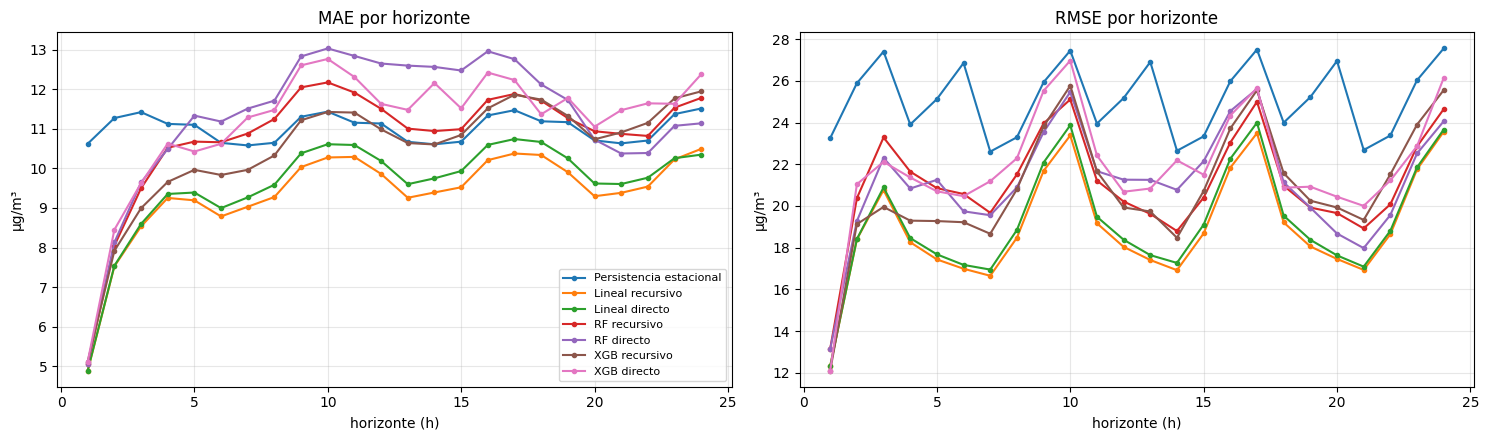

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
por_horizonte(T_est, cols_est, "MAE").plot(ax=ax[0], marker="o", ms=3, title="MAE por horizonte")
por_horizonte(T_est, cols_est, "RMSE").plot(ax=ax[1], marker="o", ms=3, title="RMSE por horizonte", legend=False)
for a in ax:
    a.set_xlabel("horizonte (h)"); a.set_ylabel("µg/m³"); a.grid(alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretación.** La estrategia recursiva obtiene menor error que la directa en las tres familias (lineal: 9.37 frente a 9.60 de MAE; RF: 10.82 frente a 11.30; XGBoost: 10.49 frente a 11.17) y además es varias veces más rápida, por lo que se adopta para todas las familias. Por horizonte, el lineal recursivo tiene el menor MAE en casi todo el horizonte, mientras que los modelos de árboles con hiperparámetros por defecto quedan por encima de la persistencia en algunos horizontes intermedios. Las oscilaciones del RMSE se repiten cada 7 horas (t+3, t+10, t+17, t+24), coincidiendo con el avance entre folds (`fold_stride=7`), lo que indica un efecto del diseño de evaluación sobre pocos episodios extremos y no un comportamiento real del horizonte.

## 8. Ajuste de hiperparámetros de Random Forest y XGBoost

Con la estrategia recursiva y los rezagos elegidos, se ajustan los hiperparámetros de los modelos de árboles mediante una grilla pequeña y razonada, como recomienda la guía (9.3). Todas las combinaciones usan los mismos folds y los mismos casos comunes, y se elige la de menor RMSE. El modelo lineal no tiene hiperparámetros que ajustar.

- **Random Forest:** profundidad máxima, tamaño mínimo de hoja y proporción de variables por división, para controlar el sobreajuste de los árboles completos.
- **XGBoost:** número de árboles, profundidad y tasa de aprendizaje, que controlan la complejidad del boosting.

In [ ]:
from sklearn.model_selection import ParameterGrid

GRILLAS = {
    "RF":  (RandomForestRegressor, {"n_estimators": [200], "max_depth": [5, 10, 20],
                                    "min_samples_leaf": [1, 10], "max_features": [1.0, 0.5]}),
    "XGB": (XGBRegressor, {"n_estimators": [300, 600], "max_depth": [3, 5],
                           "learning_rate": [0.03, 0.1], "subsample": [0.8], "colsample_bytree": [0.8]}),
}

modelos_grid, params_grid = {}, {}
for fam, (Est, grilla) in GRILLAS.items():
    for p in ParameterGrid(grilla):
        nombre = f"{fam} | " + ", ".join(f"{k}={v}" for k, v in p.items())
        params_grid[nombre] = p
        modelos_grid[nombre] = ForecasterRecursive(Est(random_state=SEED, n_jobs=-1, **p),
                                                   lags=CANDIDATOS[mejores_lags[fam]],
                                                   dropna_from_series=True)
preds_grid = backtest(modelos_grid)
T_grid, cols_grid = tabla_comun(preds_grid)
res_grid = metricas(T_grid, cols_grid)
res_grid["familia"] = [c.split(" | ")[0] for c in res_grid.index]
res_grid.sort_values(["familia", "RMSE"])

RF | max_depth=5, max_features=1.0, min_samples_leaf=1, n_estimators=200: 49 s
RF | max_depth=5, max_features=1.0, min_samples_leaf=10, n_estimators=200: 56 s
RF | max_depth=5, max_features=0.5, min_samples_leaf=1, n_estimators=200: 48 s
RF | max_depth=5, max_features=0.5, min_samples_leaf=10, n_estimators=200: 48 s
RF | max_depth=10, max_features=1.0, min_samples_leaf=1, n_estimators=200: 55 s
RF | max_depth=10, max_features=1.0, min_samples_leaf=10, n_estimators=200: 54 s
RF | max_depth=10, max_features=0.5, min_samples_leaf=1, n_estimators=200: 52 s
RF | max_depth=10, max_features=0.5, min_samples_leaf=10, n_estimators=200: 52 s
RF | max_depth=20, max_features=1.0, min_samples_leaf=1, n_estimators=200: 65 s
RF | max_depth=20, max_features=1.0, min_samples_leaf=10, n_estimators=200: 56 s
RF | max_depth=20, max_features=0.5, min_samples_leaf=1, n_estimators=200: 61 s
RF | max_depth=20, max_features=0.5, min_samples_leaf=10, n_estimators=200: 53 s
XGB | colsample_bytree=0.8, learning_r

,MAE,RMSE,familia
"RF | max_depth=5, max_features=0.5, min_samples_leaf=1, n_estimators=200",9.18,19.79,RF
"RF | max_depth=10, max_features=0.5, min_samples_leaf=1, n_estimators=200",9.70,20.13,RF
"RF | max_depth=5, max_features=0.5, min_samples_leaf=10, n_estimators=200",9.27,20.21,RF
"RF | max_depth=20, max_features=0.5, min_samples_leaf=10, n_estimators=200",10.45,20.64,RF
"RF | max_depth=20, max_features=0.5, min_samples_leaf=1, n_estimators=200",10.73,20.72,RF
"RF | max_depth=10, max_features=1.0, min_samples_leaf=1, n_estimators=200",10.12,20.98,RF
"RF | max_depth=5, max_features=1.0, min_samples_leaf=1, n_estimators=200",10.11,21.03,RF
"RF | max_depth=10, max_features=0.5, min_samples_leaf=10, n_estimators=200",10.23,21.07,RF
"RF | max_depth=20, max_features=1.0, min_samples_leaf=1, n_estimators=200",10.80,21.32,RF
"RF | max_depth=5, max_features=1.0, min_samples_leaf=10, n_estimators=200",10.31,22.43,RF


In [ ]:
mejores_params = {fam: params_grid[res_grid[res_grid["familia"] == fam]["RMSE"].idxmin()]
                  for fam in GRILLAS}
mejores_params

{'RF': {'max_depth': 5,
  'max_features': 0.5,
  'min_samples_leaf': 1,
  'n_estimators': 200},
 'XGB': {'colsample_bytree': 0.8,
  'learning_rate': 0.03,
  'max_depth': 5,
  'n_estimators': 300,
  'subsample': 0.8}}

**Interpretación.** La regularización mejora claramente a los modelos de árboles: Random Forest pasa de MAE 10.82 / RMSE 21.20 a 9.18 / 19.79 con árboles de profundidad 5 y la mitad de las variables por división, y XGBoost de 10.49 / 21.02 a 9.82 / 20.41 con una tasa de aprendizaje de 0.03. Con los valores por defecto, ambos sobreajustaban una serie ruidosa. Random Forest ajustado obtiene el menor MAE de todos los modelos, aunque el lineal mantiene el menor RMSE. Como los mejores valores quedaron en el borde de la grilla, se amplía la búsqueda en esa dirección y se revisa la elección de rezagos con los hiperparámetros ajustados.

### 8.1 Grilla ampliada
Se amplía la grilla en la dirección en que mejoró el error: árboles menos profundos y menos variables por división para Random Forest, y tasas de aprendizaje menores y árboles más profundos para XGBoost. La grilla incluye la mejor combinación anterior, de modo que el resultado no puede empeorar.

In [ ]:
def correr_grilla(grillas, lags_por_familia):
    modelos, params = {}, {}
    for fam, (Est, grilla) in grillas.items():
        for p in ParameterGrid(grilla):
            nombre = f"{fam} | " + ", ".join(f"{k}={v}" for k, v in p.items())
            params[nombre] = p
            modelos[nombre] = ForecasterRecursive(Est(random_state=SEED, n_jobs=-1, **p),
                                                  lags=CANDIDATOS[lags_por_familia[fam]],
                                                  dropna_from_series=True)
    T, cols = tabla_comun(backtest(modelos))
    res = metricas(T, cols)
    res["familia"] = [c.split(" | ")[0] for c in res.index]
    mejores = {fam: params[res[res["familia"] == fam]["RMSE"].idxmin()] for fam in grillas}
    return res.sort_values(["familia", "RMSE"]), mejores

GRILLAS_2 = {
    "RF":  (RandomForestRegressor, {"n_estimators": [200], "max_depth": [3, 4, 5, 6, 7],
                                    "max_features": [0.3, 0.5], "min_samples_leaf": [1, 5]}),
    "XGB": (XGBRegressor, {"n_estimators": [300, 600], "max_depth": [5, 7],
                           "learning_rate": [0.01, 0.03], "subsample": [0.8], "colsample_bytree": [0.8]}),
}
res_grid2, mejores_params = correr_grilla(GRILLAS_2, mejores_lags)
display(res_grid2.groupby("familia").head(5))
mejores_params

RF | max_depth=3, max_features=0.3, min_samples_leaf=1, n_estimators=200: 51 s
RF | max_depth=3, max_features=0.3, min_samples_leaf=5, n_estimators=200: 47 s
RF | max_depth=3, max_features=0.5, min_samples_leaf=1, n_estimators=200: 48 s
RF | max_depth=3, max_features=0.5, min_samples_leaf=5, n_estimators=200: 48 s
RF | max_depth=4, max_features=0.3, min_samples_leaf=1, n_estimators=200: 48 s
RF | max_depth=4, max_features=0.3, min_samples_leaf=5, n_estimators=200: 47 s
RF | max_depth=4, max_features=0.5, min_samples_leaf=1, n_estimators=200: 48 s
RF | max_depth=4, max_features=0.5, min_samples_leaf=5, n_estimators=200: 48 s
RF | max_depth=5, max_features=0.3, min_samples_leaf=1, n_estimators=200: 47 s
RF | max_depth=5, max_features=0.3, min_samples_leaf=5, n_estimators=200: 48 s
RF | max_depth=5, max_features=0.5, min_samples_leaf=1, n_estimators=200: 48 s
RF | max_depth=5, max_features=0.5, min_samples_leaf=5, n_estimators=200: 47 s
RF | max_depth=6, max_features=0.3, min_samples_leaf

,MAE,RMSE,familia
"RF | max_depth=4, max_features=0.3, min_samples_leaf=1, n_estimators=200",8.92,19.53,RF
"RF | max_depth=4, max_features=0.3, min_samples_leaf=5, n_estimators=200",8.91,19.54,RF
"RF | max_depth=3, max_features=0.3, min_samples_leaf=5, n_estimators=200",8.95,19.58,RF
"RF | max_depth=3, max_features=0.3, min_samples_leaf=1, n_estimators=200",8.95,19.59,RF
"RF | max_depth=5, max_features=0.3, min_samples_leaf=1, n_estimators=200",8.99,19.65,RF
"XGB | colsample_bytree=0.8, learning_rate=0.01, max_depth=7, n_estimators=300, subsample=0.8",9.84,19.60,XGB
"XGB | colsample_bytree=0.8, learning_rate=0.01, max_depth=5, n_estimators=300, subsample=0.8",9.93,19.66,XGB
"XGB | colsample_bytree=0.8, learning_rate=0.01, max_depth=5, n_estimators=600, subsample=0.8",9.79,20.18,XGB
"XGB | colsample_bytree=0.8, learning_rate=0.01, max_depth=7, n_estimators=600, subsample=0.8",9.94,20.33,XGB
"XGB | colsample_bytree=0.8, learning_rate=0.03, max_depth=5, n_estimators=300, subsample=0.8",9.82,20.41,XGB


{'RF': {'max_depth': 4,
  'max_features': 0.3,
  'min_samples_leaf': 1,
  'n_estimators': 200},
 'XGB': {'colsample_bytree': 0.8,
  'learning_rate': 0.01,
  'max_depth': 7,
  'n_estimators': 300,
  'subsample': 0.8}}

### 8.2 Revisión de rezagos con hiperparámetros ajustados
Los rezagos de Random Forest y XGBoost se eligieron con hiperparámetros por defecto. Con los modelos ya regularizados, se vuelven a comparar los conjuntos más competitivos de la sección 6 para confirmar o corregir esa elección.

In [ ]:
REVISAR = ["1-3, 24, 48 (EDA)", "1-24, 48", "1-24, 48, 168"]
EST_CLASE = {"RF": RandomForestRegressor, "XGB": XGBRegressor}

modelos_rev = {f"{fam} | {n}": ForecasterRecursive(Est(random_state=SEED, n_jobs=-1, **mejores_params[fam]),
                                                   lags=CANDIDATOS[n], dropna_from_series=True)
               for fam, Est in EST_CLASE.items() for n in REVISAR}
T_rev, cols_rev = tabla_comun(backtest(modelos_rev))
res_rev = metricas(T_rev, cols_rev)
res_rev.index = pd.MultiIndex.from_tuples([c.split(" | ") for c in res_rev.index], names=["modelo", "rezagos"])
res_rev = res_rev.unstack("modelo").reindex(REVISAR)
display(res_rev)

for fam in EST_CLASE:
    mejores_lags[fam] = res_rev["RMSE"][fam].idxmin()
mejores_lags

RF | 1-3, 24, 48 (EDA): 49 s
RF | 1-24, 48: 50 s
RF | 1-24, 48, 168: 50 s
XGB | 1-3, 24, 48 (EDA): 19 s
XGB | 1-24, 48: 23 s
XGB | 1-24, 48, 168: 23 s
Casos comunes: 25563 de 30006 (85.2%)


MAE          RMSE       
modelo               RF    XGB     RF    XGB
rezagos                                     
1-3, 24, 48 (EDA)  8.92  10.26  19.53  20.18
1-24, 48           8.79   9.84  19.66  19.60
1-24, 48, 168      8.84   9.60  19.63  19.37

,0
modelo,
Lineal,"1-24, 48, 168"
RF,"1-3, 24, 48 (EDA)"
XGB,"1-24, 48, 168"


**Interpretación.** Con la grilla ampliada, Random Forest alcanza una meseta: las mejores combinaciones (profundidad 3 a 5, 30 % de las variables por división) difieren en menos de 0.15 de RMSE, y se adopta profundidad 4 (MAE 8.92, RMSE 19.53). XGBoost mejora con una tasa de aprendizaje de 0.01 (RMSE 19.60). Aunque algunos valores quedan en el borde de la grilla, las diferencias son de centésimas, por lo que no se amplía más la búsqueda para no ajustar la configuración al ruido de los folds de validación. Al revisar los rezagos con los modelos ajustados, Random Forest mantiene 1-3, 24, 48 y XGBoost mejora con 1-24, 48, 168 (MAE 9.60, RMSE 19.37). En RMSE, el lineal sigue siendo el mejor (19.15), mientras que Random Forest obtiene el menor MAE (8.92).

## 9. Variables de calendario

Se evalúa si agregar variables de calendario mejora a los mejores modelos de cada familia. Son variables conocidas a futuro, por lo que pueden usarse en todo el horizonte sin fuga de información, pero el modelo deja de ser estrictamente univariante; por eso se reporta aparte como "univariante + calendario".

Se prueban, de forma incremental: solo la hora del día (la variable que más respalda el EDA), hora + día de la semana + mes, y todas más el día del mes. Para Random Forest y XGBoost se usan como enteros. Para el lineal se codifican de forma cíclica (seno y coseno), porque un número de 0 a 23 no tiene relación lineal con el nivel y la hora 23 está cerca de la hora 0 (guía, 10.3).

In [ ]:
idx = y_modelo.index
cal = pd.DataFrame({"hora": idx.hour, "dia_semana": idx.dayofweek,
                    "mes": idx.month, "dia_mes": idx.day}, index=idx)

PERIODOS = {"hora": 24, "dia_semana": 7, "mes": 12, "dia_mes": 31}
cal_cic = pd.DataFrame(index=idx)
for c, p in PERIODOS.items():
    cal_cic[f"{c}_sin"] = np.sin(2 * np.pi * cal[c] / p)
    cal_cic[f"{c}_cos"] = np.cos(2 * np.pi * cal[c] / p)

VARIANTES = {
    "sin calendario":        [],
    "hora":                  ["hora"],
    "hora, día semana, mes": ["hora", "dia_semana", "mes"],
    "todas (+ día del mes)": ["hora", "dia_semana", "mes", "dia_mes"],
}

def exog_para(fam, variables):
    if not variables:
        return None
    if fam == "Lineal":
        return cal_cic[[f"{v}_{t}" for v in variables for t in ("sin", "cos")]]
    return cal[variables]

In [ ]:
def backtest(modelos, exogs=None):   # misma función que antes, ahora admite variables exógenas
    preds = {}
    for nombre, f in modelos.items():
        t = time.time()
        _, p = backtesting_forecaster(f, y=y_modelo, exog=(exogs or {}).get(nombre), cv=cv,
                                      metric=sin_metrica, show_progress=False, suppress_warnings=True)
        assert (p.index == base.index).all()
        preds[nombre] = p["pred"]
        print(f"{nombre}: {time.time() - t:.0f} s")
    return preds

EST_FINAL = {
    "Lineal": lambda: LinearRegression(),
    "RF":     lambda: RandomForestRegressor(random_state=SEED, n_jobs=-1, **mejores_params["RF"]),
    "XGB":    lambda: XGBRegressor(random_state=SEED, n_jobs=-1, **mejores_params["XGB"]),
}

modelos_cal, exogs_cal = {}, {}
for fam, est in EST_FINAL.items():
    for v, variables in VARIANTES.items():
        nombre = f"{fam} | {v}"
        modelos_cal[nombre] = ForecasterRecursive(est(), lags=CANDIDATOS[mejores_lags[fam]],
                                                  dropna_from_series=True)
        exogs_cal[nombre] = exog_para(fam, variables)

preds_cal = backtest(modelos_cal, exogs_cal)
T_cal, cols_cal = tabla_comun(preds_cal)
res_cal = metricas(T_cal, cols_cal)
res_cal.index = pd.MultiIndex.from_tuples([c.split(" | ") for c in res_cal.index],
                                          names=["modelo", "calendario"])
res_cal = res_cal.unstack("modelo").reindex(VARIANTES)
res_cal

Lineal | sin calendario: 2 s
Lineal | hora: 2 s
Lineal | hora, día semana, mes: 3 s
Lineal | todas (+ día del mes): 2 s
RF | sin calendario: 48 s
RF | hora: 52 s
RF | hora, día semana, mes: 49 s
RF | todas (+ día del mes): 49 s
XGB | sin calendario: 23 s
XGB | hora: 24 s
XGB | hora, día semana, mes: 24 s
XGB | todas (+ día del mes): 24 s
Casos comunes: 25563 de 30006 (85.2%)


MAE               RMSE              
modelo                Lineal    RF   XGB Lineal     RF    XGB
calendario                                                   
sin calendario          9.37  8.92  9.60  19.15  19.53  19.37
hora                    9.43  8.79  9.72  18.96  19.23  19.06
hora, día semana, mes   9.59  8.57  9.68  18.89  19.27  19.06
todas (+ día del mes)   9.59  8.59  9.64  18.89  19.23  19.12

**Interpretación.** Agregar la hora del día reduce el RMSE en las tres familias (lineal: 19.15 a 18.96; Random Forest: 19.53 a 19.23; XGBoost: 19.37 a 19.06), lo que es consistente con el ciclo diario observado en el EDA. Sumar el día de la semana y el mes no produce mejoras consistentes: los cambios son pequeños y de signo distinto según la métrica y la familia. El día del mes no aporta en ningún modelo, lo que confirma con backtesting lo observado en el EDA. Por parsimonia, se adopta solo la hora del día como variable de calendario.

## 10. Comparación final y selección del mejor modelo univariante

Se comparan sobre los mismos casos comunes la persistencia estacional, el mejor modelo de cada familia en versión univariante pura y su versión con la hora del día. Se reportan MAE y RMSE globales, la mejora relativa frente a la persistencia, el error por horizonte y ejemplos de pronóstico contra el valor real. No se vuelve a entrenar nada: se reutilizan las predicciones ya obtenidas en las secciones anteriores.

In [ ]:
FINALES = {
    "Persistencia estacional": preds_ref["Persistencia estacional"],
    "Lineal":        preds_cal["Lineal | sin calendario"],
    "RF":            preds_cal["RF | sin calendario"],
    "XGB":           preds_cal["XGB | sin calendario"],
    "Lineal + hora": preds_cal["Lineal | hora"],
    "RF + hora":     preds_cal["RF | hora"],
    "XGB + hora":    preds_cal["XGB | hora"],
}
T_fin, cols_fin = tabla_comun(FINALES)
res_fin = metricas(T_fin, cols_fin)
ref_p = res_fin.loc["Persistencia estacional"]
res_fin["mejora MAE (%)"]  = (100 * (1 - res_fin["MAE"]  / ref_p["MAE"])).round(1)
res_fin["mejora RMSE (%)"] = (100 * (1 - res_fin["RMSE"] / ref_p["RMSE"])).round(1)
res_fin

Casos comunes: 25563 de 30006 (85.2%)


,MAE,RMSE,mejora MAE (%),mejora RMSE (%)
Persistencia estacional,11.02,25.18,0.0,0.0
Lineal,9.37,19.15,15.0,23.9
RF,8.92,19.53,19.1,22.4
XGB,9.60,19.37,12.9,23.1
Lineal + hora,9.43,18.96,14.4,24.7
RF + hora,8.79,19.23,20.2,23.6
XGB + hora,9.72,19.06,11.8,24.3


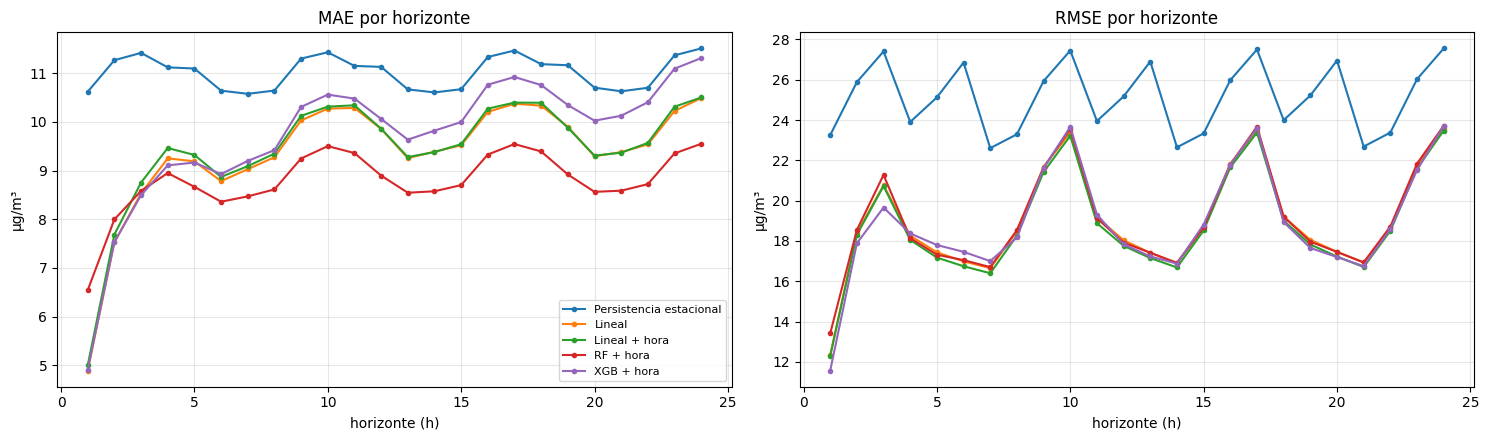

In [ ]:
sel = ["Persistencia estacional", "Lineal", "Lineal + hora", "RF + hora", "XGB + hora"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
por_horizonte(T_fin, sel, "MAE").plot(ax=ax[0], marker="o", ms=3, title="MAE por horizonte")
por_horizonte(T_fin, sel, "RMSE").plot(ax=ax[1], marker="o", ms=3, title="RMSE por horizonte", legend=False)
for a in ax:
    a.set_xlabel("horizonte (h)"); a.set_ylabel("µg/m³"); a.grid(alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

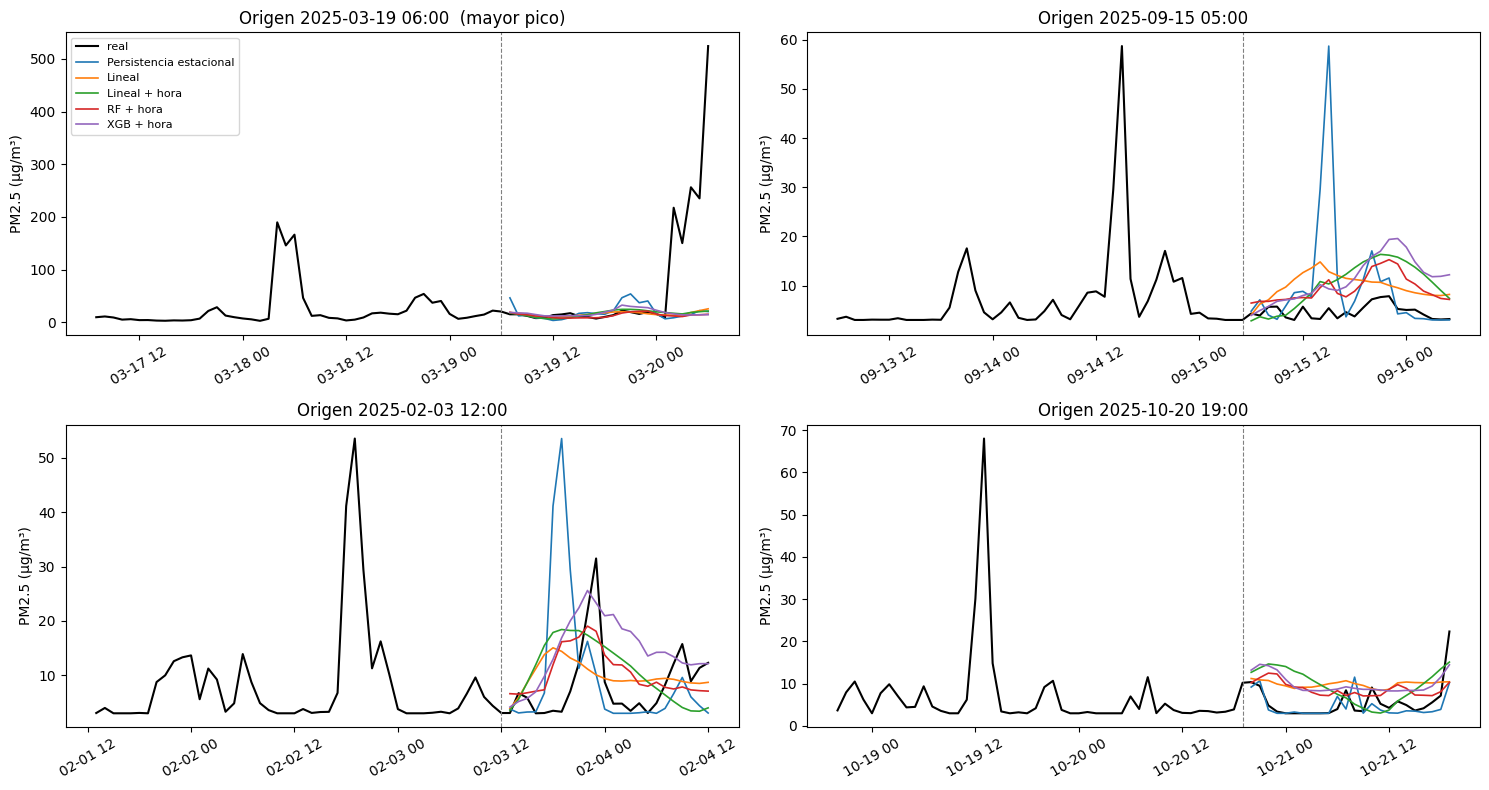

In [ ]:
rng = np.random.default_rng(SEED)
ok = T_fin.groupby("fold")["comun"].all()
folds_ok = ok[ok].index
f_pico = T_fin[T_fin["fold"].isin(folds_ok)].groupby("fold")["real"].max().idxmax()
elegidos = [f_pico] + list(rng.choice(folds_ok.drop(f_pico), 3, replace=False))

fig, axs = plt.subplots(2, 2, figsize=(15, 8))
for ax, f in zip(axs.flat, elegidos):
    seg = T_fin[T_fin["fold"] == f]
    origen = seg["origen"].iloc[0]
    ax.plot(y_real[origen - pd.Timedelta("47h"): seg.index[-1]], color="k", lw=1.5, label="real")
    for c in sel:
        ax.plot(seg[c], lw=1.2, label=c)
    ax.axvline(origen, color="gray", ls="--", lw=0.8)
    ax.set_title(f"Origen {origen:%Y-%m-%d %H:%M}" + ("  (mayor pico)" if f == f_pico else ""))
    ax.set_ylabel("PM2.5 (µg/m³)"); ax.tick_params(axis="x", labelrotation=30)
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()